# 05 · Проверка устойчивости выводов и итоговая сборка

Анализ в ноутбуках 00–04 закончен. Здесь мы делаем то, что обычно пропускают:
**проверяем, выдерживают ли главные выводы смену спецификации**.
Кейс требует «data-driven выводов, а не несколько красивых графиков»,
поэтому каждое число, которое пойдёт на слайд, должно иметь:

1. источник (таблица в `outputs/tables`);
2. проверку на устойчивость (другая спецификация / подвыборка);
3. явную формулировку, чего утверждать **нельзя**.

## Что проверяем
* **A. Эффект доставки (PSM)** — не является ли +3,2 п.п. артефактом калипера и выбора контроля.
* **B. Разрыв S4 vs S5** — значим ли наивный «×3,2» и чем он объясняется.
* **C. Разрыв Маркет vs Партнёр** — это состав трафика или механика карточки.
* **D. Тренды за месяц** — не объясняются ли они структурой дней недели.
* **E. Контентный вывод** — держится ли «товарный охват выше в 1,9 раза» без выбросов и рекламодателей.

In [1]:
import sys, warnings, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vkcase import data, analysis as an, viz
from vkcase.config import VK, PARTNER, GOOD, BAD, GREY

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 60)
%matplotlib inline

d = data.load_all()
b = an.add_scenario_segment(d["biz"])
kn = json.loads((data.OUT / "key_numbers.json").read_text(encoding="utf-8"))

print(f"Сообществ: {len(b):,} | ключевых блоков в key_numbers.json: {len(kn)}")

Сообществ: 9,754 | ключевых блоков в key_numbers.json: 6


## 1. Эффект доставки: PSM при разных калиперах и на разных контролях

В ноутбуке 02 базовая спецификация — контроль только среди сообществ с чекаутом (S4),
калипер 0,2 SD логита propensity score. Проверяем 8 комбинаций:
контроль «с чекаутом» / «весь каталог» × калипер 0,05 / 0,1 / 0,2 / 0,4.

In [2]:
specs = []
for spec_name, restrict in [("контроль: с чекаутом", {"checkout": 1}),
                            ("контроль: весь каталог", None)]:
    for cm in [0.05, 0.1, 0.2, 0.4]:
        r = an.psm_effect(b, treatment="delivery", restrict=restrict, n_boot=400, caliper_mult=cm)
        e = r["effects"].set_index("outcome")
        specs.append({
            "спецификация": spec_name, "калипер (SD)": cm,
            "пар": r["n_matched_pairs"],
            "ATT активации, п.п.": e.loc["sell_rate", "ATT"] * 100,
            "ДИ низ, п.п.": e.loc["sell_rate", "ATT_ci_low"] * 100,
            "ДИ верх, п.п.": e.loc["sell_rate", "ATT_ci_high"] * 100,
            "ATT заказов/бизнес": e.loc["orders_per_biz", "ATT"],
            "ATT GMV/бизнес, ₽": e.loc["gmv_per_biz", "ATT"],
        })
psm_grid = pd.DataFrame(specs)
data.save_table(psm_grid, "05_psm_robustness")
psm_grid.round(3)

,спецификация,калипер (SD),пар,"ATT активации, п.п.","ДИ низ, п.п.","ДИ верх, п.п.",ATT заказов/бизнес,"ATT GMV/бизнес, ₽"
0,контроль: с чекаутом,0.05,704,2.841,-0.710,6.396,-0.283,-323.412
1,контроль: с чекаутом,0.10,708,2.966,-0.569,7.345,-0.463,-167.912
2,контроль: с чекаутом,0.20,714,3.221,-0.424,7.143,-0.595,1303.793
3,контроль: с чекаутом,0.40,717,3.487,-0.003,7.392,-0.556,1546.078
4,контроль: весь каталог,0.05,801,3.121,-0.006,6.117,-1.106,1990.056
5,контроль: весь каталог,0.10,802,2.993,-0.125,6.116,-1.111,1929.283
6,контроль: весь каталог,0.20,803,2.989,-0.006,5.856,-1.107,1998.176
7,контроль: весь каталог,0.40,806,3.226,-0.499,6.458,-1.074,2127.029


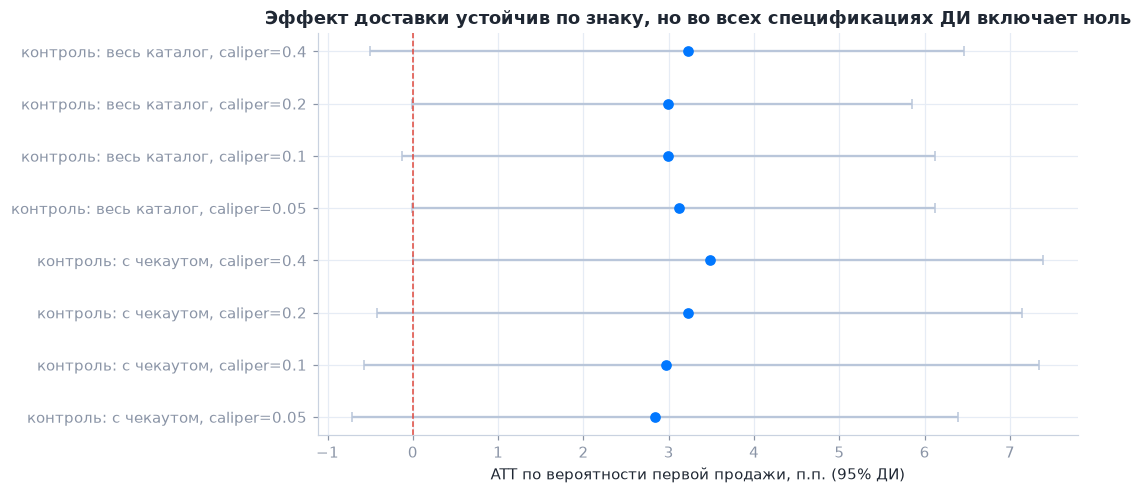

WindowsPath('C:/Users/Степан/Desktop/workspace/outputs/figures/05_psm_robustness.png')

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(psm_grid))
ax.errorbar(psm_grid["ATT активации, п.п."], y,
            xerr=[psm_grid["ATT активации, п.п."] - psm_grid["ДИ низ, п.п."],
                  psm_grid["ДИ верх, п.п."] - psm_grid["ATT активации, п.п."]],
            fmt="o", color=VK, ecolor="#B9C6DA", capsize=3, ms=6)
ax.axvline(0, color=BAD, ls="--", lw=1)
ax.set_yticks(y, [f"{r['спецификация']}, caliper={r['калипер (SD)']}" for _, r in psm_grid.iterrows()])
ax.set_xlabel("ATT по вероятности первой продажи, п.п. (95% ДИ)")
ax.set_title("Эффект доставки устойчив по знаку, но во всех спецификациях ДИ включает ноль")
fig.tight_layout(); viz.save(fig, "05_psm_robustness")

**Чтение результата.**
* Точечная оценка активации **+2,8…+3,5 п.п.** во всех 8 спецификациях — направление устойчиво.
* **Во всех 8 спецификациях 95% ДИ включает ноль** (нижние границы −0,7…0,0 п.п.).
* По **объёму заказов ATT отрицательный** (−0,3…−1,1 заказа на бизнес) во всех спецификациях.
* По GMV — также без положительного эффекта.

Отсюда корректная формулировка: **доставка снимает барьер первой сделки, но не создаёт спрос.**
Обещать «подключим доставку — продажи вырастут втрое» нельзя; проверять A/B-тестом.

Оговорка: интервал построен парным бутстрэпом по сопоставленным парам и **не учитывает
неопределённость самого сопоставления**; с её учётом ДИ был бы шире, то есть вывод
«эффект не доказан» только усиливается. В ковариатах нет тематики — баланс по ней не гарантирован.

## 2. S4 vs S5: наивный разрыв значим, но группы несопоставимы

«Сообщества с доставкой продают в 3,2 раза чаще» — проверим значимость и состав групп.
Разница долей тестируется z-тестом, интервал — методом Newcombe.

In [4]:
prof = an.segment_profile(b).set_index("segment")
s4 = prof.loc["S4. Каталог + чекаут"]
s5 = prof.loc["S5. Каталог + чекаут + доставка"]
s56_n = s5.n + prof.loc["S6. Полный стек (+оплата)", "n"]
s56_sellers = s5.sellers + prof.loc["S6. Полный стек (+оплата)", "sellers"]

tp_s5 = an.two_prop_test(s5.sellers, s5.n, s4.sellers, s4.n)
tp_s56 = an.two_prop_test(s56_sellers, s56_n, s4.sellers, s4.n)
gap_test = pd.DataFrame([
    {"сравнение": "S5 (доставка) vs S4 (без доставки)",
     "доля 1": tp_s5["p1"], "доля 2": tp_s5["p2"], "разница, п.п.": tp_s5["diff"] * 100,
     "ДИ низ, п.п.": tp_s5["diff_ci_low"] * 100, "ДИ верх, п.п.": tp_s5["diff_ci_high"] * 100,
     "отношение": tp_s5["ratio"], "p-value": tp_s5["p_value"]},
    {"сравнение": "S5+S6 vs S4",
     "доля 1": tp_s56["p1"], "доля 2": tp_s56["p2"], "разница, п.п.": tp_s56["diff"] * 100,
     "ДИ низ, п.п.": tp_s56["diff_ci_low"] * 100, "ДИ верх, п.п.": tp_s56["diff_ci_high"] * 100,
     "отношение": tp_s56["ratio"], "p-value": tp_s56["p_value"]},
])
data.save_table(gap_test, "05_segment_gap_test")
gap_test.round(4)

,сравнение,доля 1,доля 2,"разница, п.п.","ДИ низ, п.п.","ДИ верх, п.п.",отношение,p-value
0,S5 (доставка) vs S4 (без доставки),0.1712,0.053,11.8154,8.9301,15.0565,3.2274,0.0
1,S5+S6 vs S4,0.1711,0.053,11.8025,9.0827,14.8241,3.2250,0.0


In [5]:
comp = pd.DataFrame([
    ["медиана подписчиков", s4.subs_median, s5.subs_median],
    ["медиана активных SKU", s4.sku_median, s5.sku_median],
    ["медиана публикаций за 30 дней", s4.content_median, s5.content_median],
    ["доля с товарным контентом", s4.prod_content_share, s5.prod_content_share],
    ["доля продающих", s4.sell_rate, s5.sell_rate],
], columns=["показатель", "S4. Каталог + чекаут", "S5. Каталог + доставка"])
data.save_table(comp, "05_s4_vs_s5_profile")
comp.round(4)

,показатель,S4. Каталог + чекаут,S5. Каталог + доставка
0,медиана подписчиков,665.000,1000.0000
1,медиана активных SKU,9.000,39.0000
2,медиана публикаций за 30 дней,3.000,5.0000
3,доля с товарным контентом,0.037,0.1248
4,доля продающих,0.053,0.1712


**Вывод.** Наивный разрыв **статистически значим** (+11,8 п.п., ×3,2, p < 0,001),
но группы различаются по ассортименту в 4,3 раза (39 vs 9 SKU) и по охвату.
Значит, тест подтверждает не эффект инструмента, а **разную зрелость продавцов**.
Именно поэтому основной оценкой остаётся PSM, а не наивное сравнение.

## 3. Разрыв Маркет vs Партнёр: состав трафика или механика карточки?

Конверсия открытие → заказ: **0,21% у Маркета против 5,67% у Партнёра** (×26).
Проверяем разложение:

`конверсия = Σ (доля категории × конверсия внутри категории)`

* **эффект состава** — если бы у Маркета был микс открытий Партнёра, но его собственные
  внутрикатегорийные конверсии;
* **эффект механики** — всё, что остаётся и воспроизводится внутри каждой категории.

In [6]:
dec = an.category_mix_decomposition(d["categories"])
data.save_table(dec["summary"], "05_gap_mix_vs_within")
data.save_table(dec["by_category"], "05_gap_by_category")
print(f"Категорий в расчёте: {dec['n_categories']}")
print(f"Конверсия Маркета: {dec['conv_vk']:.4%} | Партнёра: {dec['conv_pt']:.4%} | "
      f"контрфактика (микс Партнёра × механика Маркета): {dec['conv_counterfactual']:.4%}")
dec["summary"].round(4)

Категорий в расчёте: 17
Конверсия Маркета: 0.2251% | Партнёра: 5.1101% | контрфактика (микс Партнёра × механика Маркета): 0.1456%


,компонента,ratio,share_of_log_gap
0,Состав трафика (какие категории смотрят),0.6468,-0.1396
1,Механика внутри категорий (карточка → заказ),35.0949,1.1396
2,Итого (Партнёр / Маркет),22.6987,1.0000


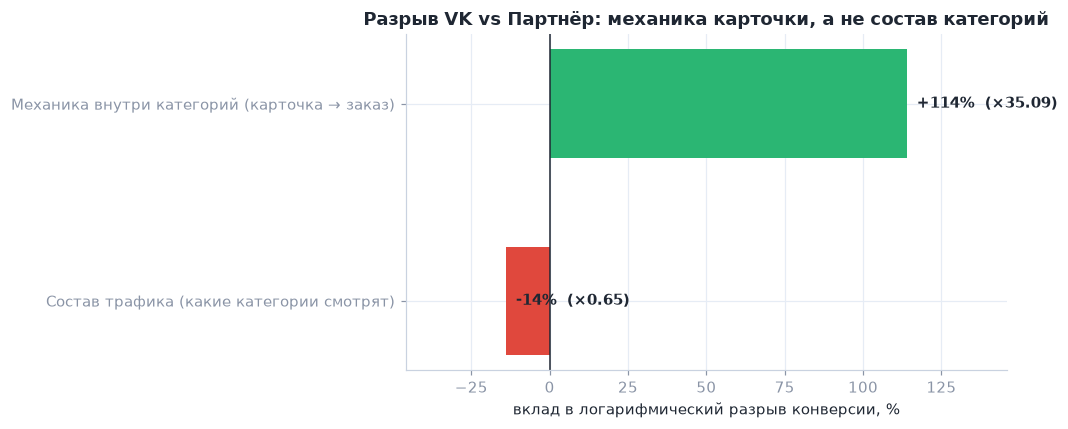

WindowsPath('C:/Users/Степан/Desktop/workspace/outputs/figures/05_gap_mix_vs_within.png')

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 4))
s = dec["summary"].iloc[:2]
colors = [BAD if v < 0 else GOOD for v in s.share_of_log_gap]
ax.barh(s.компонента, s.share_of_log_gap * 100, color=colors, height=0.55)
for i, (v, r) in enumerate(zip(s.share_of_log_gap * 100, s.ratio)):
    ax.text(v, i, f"  {v:+.0f}%  (×{r:.2f})", va="center", fontweight="bold")
ax.axvline(0, color="#1F2733", lw=1)
ax.set_xlabel("вклад в логарифмический разрыв конверсии, %")
ax.set_title("Разрыв VK vs Партнёр: механика карточки, а не состав категорий")
ax.margins(x=0.25)
fig.tight_layout(); viz.save(fig, "05_gap_mix_vs_within")

**Результат, меняющий акцент в презентации.**
* Состав трафика объясняет **−14%** логарифмического разрыва: он скорее **помогает** Маркету,
  потому что у него выше доля «Продуктов питания» и ниже — «Ремонта».
* Механика внутри категорий объясняет **114%**: разрыв **воспроизводится во всех товарных
  категориях** (отношение конверсий ×6…×315); исключение — служебная корзина «Другое»,
  у Партнёра в ней ноль заказов.

То есть **46% «мёртвого трафика» — это проблема объёма и релевантности ассортимента,
но не объяснение низкой конверсии**. Главный вывод ноутбука 03 сохраняется:
карточка Маркета не доводит до сделки. Оговорка: суммы заказов по категориям расходятся
с итогами на 5–7%, поэтому смотрим на структуру, а не на абсолютные значения.
В разложение входят 17 категорий, где есть открытия у обоих сегментов, поэтому итоговое
отношение здесь 22,7, а не 26,5 по полным данным; на вывод о вкладе механики это не влияет.

## 4. Тренды: проверка на календарный артефакт

«Заказы Маркета −10,7%, Партнёра +18% за месяц» — это сравнение первых и последних 7 дней.
В 30-дневном окне такой расчёт чувствителен к тому, какие дни недели попали в края.
Оцениваем **log(метрика) ~ день + фиксированные эффекты дня недели** с HAC-ошибками.

In [8]:
metrics = ["Заказы: Маркет Вконтакте", "GMV, ₽: Маркет Вконтакте",
           "Заказы: Партнёр 1", "GMV, ₽: Партнёр 1", "Открытия карточки: Партнёр 1"]
tr = pd.DataFrame([an.trend_adjusted(d["daily"], m) for m in metrics])
tr["дневной темп, %"] = tr.daily_pct * 100
tr["ДИ низ, %/день"] = tr.daily_pct_ci_low * 100
tr["ДИ верх, %/день"] = tr.daily_pct_ci_high * 100
tr["за 30 дней, %"] = ((1 + tr.daily_pct) ** 30 - 1) * 100
tr["raw change, %"] = tr.change_pct_raw * 100
data.save_table(tr, "05_trends_adjusted")
tr[["metric", "дневной темп, %", "ДИ низ, %/день", "ДИ верх, %/день",
    "за 30 дней, %", "raw change, %", "p_value_adjusted", "p_value_raw", "r2"]].round(4)

,metric,"дневной темп, %","ДИ низ, %/день","ДИ верх, %/день","за 30 дней, %","raw change, %",p_value_adjusted,p_value_raw,r2
0,Заказы: Маркет Вконтакте,-0.4789,-0.8308,-0.1257,-13.4114,-10.6580,0.0079,0.0391,0.5783
1,"GMV, ₽: Маркет Вконтакте",-0.3467,-0.5831,-0.1097,-9.8951,-7.1152,0.0042,0.0347,0.4685
2,Заказы: Партнёр 1,0.7339,0.2752,1.1948,24.5291,17.9786,0.0017,0.0007,0.5459
3,"GMV, ₽: Партнёр 1",1.7728,1.5557,1.9904,69.4171,51.6158,0.0000,0.0000,0.9070
4,Открытия карточки: Партнёр 1,0.5429,0.1377,0.9497,17.6349,9.4431,0.0086,0.0080,0.4306


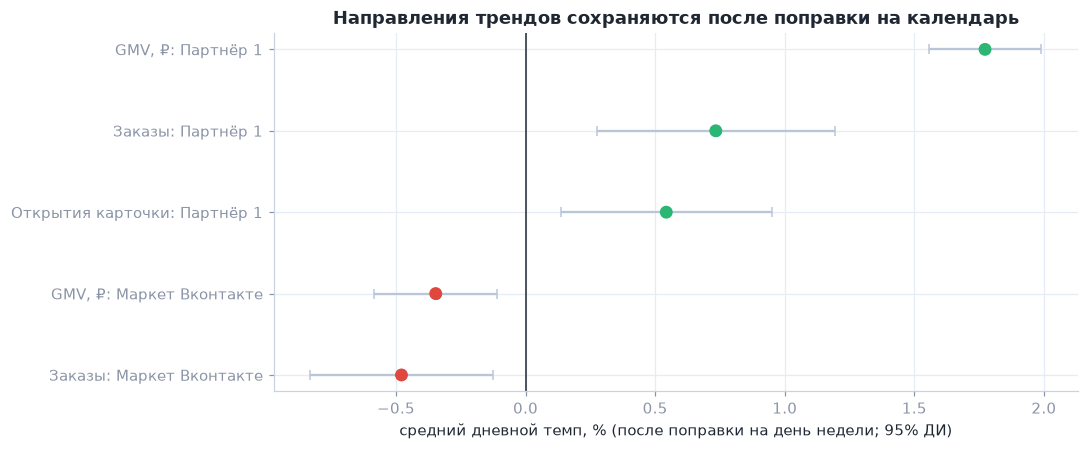

WindowsPath('C:/Users/Степан/Desktop/workspace/outputs/figures/05_trends_adjusted.png')

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
order = tr.sort_values("дневной темп, %")
y = np.arange(len(order))
colors = [GOOD if v > 0 else BAD for v in order["дневной темп, %"]]
ax.errorbar(order["дневной темп, %"], y,
            xerr=[order["дневной темп, %"] - order["ДИ низ, %/день"],
                  order["ДИ верх, %/день"] - order["дневной темп, %"]],
            fmt="o", color=VK, ecolor="#B9C6DA", capsize=3, ms=6)
ax.scatter(order["дневной темп, %"], y, c=colors, s=55, zorder=3)
ax.axvline(0, color="#1F2733", lw=1)
ax.set_yticks(y, order.metric)
ax.set_xlabel("средний дневной темп, % (после поправки на день недели; 95% ДИ)")
ax.set_title("Направления трендов сохраняются после поправки на календарь")
fig.tight_layout(); viz.save(fig, "05_trends_adjusted")

**Вывод.** Поправка на день недели **не меняет картину**:
заказы Маркета падают (≈−0,5%/день, p≈0,008), заказы Партнёра растут (≈+0,7%/день, p≈0,002),
GMV Партнёра +1,8%/день (p<0,001). За 30 дней это ≈−13% у Маркета и ≈+24% у Партнёра.
Сырые «первые 7 к последним 7» дают близкие, но чуть другие цифры (−10,7% / +18%) — их и
оставляем на слайде как простое чтение, а в приложении показываем модель.

## 5. Контентный вывод: устойчив ли он к выбросам и рекламе

Парное сравнение «товарный vs обычный контент внутри одного сообщества» дало ×1,9 по охвату.
Проверяем четыре среза: все пары, без топ-1% по подписчикам, только органика,
и оба ограничения одновременно.

In [10]:
variants = [
    ("все пары", b, False),
    ("без топ-1% по подписчикам", b[b.subs < b.subs.quantile(0.99)], False),
    ("только без рекламы", b, True),
    ("без топ-1% и без рекламы", b[b.subs < b.subs.quantile(0.99)], True),
]
rows = []
for name, frame, organic in variants:
    _, st = an.content_paired(frame, organic_only=organic)
    rows.append({
        "срез": name, "пар": st["n_paired"],
        "просмотров/пост: товарный": st["vpp_prod_median"],
        "просмотров/пост: обычный": st["vpp_reg_median"],
        "отношение": st["vpp_ratio_median"],
        "доля пар, где товарный хуже по охвату": st["vpp_prod_worse_share"],
        "отношение ER": st["er_ratio_median"],
        "p Wilcoxon (охват)": st["vpp_wilcoxon_p"],
    })
content_rob = pd.DataFrame(rows)
data.save_table(content_rob, "05_content_robustness")
content_rob.round(4)

,срез,пар,просмотров/пост: товарный,просмотров/пост: обычный,отношение,"доля пар, где товарный хуже по охвату",отношение ER,p Wilcoxon (охват)
0,все пары,299,702.1277,375.0000,1.9000,0.2977,0.5411,0.0
1,без топ-1% по подписчикам,289,650.0000,365.0794,1.9000,0.2976,0.5370,0.0
2,только без рекламы,250,600.0000,314.8707,1.9660,0.2880,0.5434,0.0
3,без топ-1% и без рекламы,245,600.0000,312.5000,1.9286,0.2898,0.5391,0.0


**Вывод.** Отношение охвата держится на уровне **1,90–1,97** во всех срезах,
отношение ER — **0,54** (товарный хуже по вовлечению). Это не эффект нескольких крупных
сообществ и не эффект рекламодателей.

## 6. Сводка чисел для защиты

Каждое число ниже либо посчитано в ноутбуках 00–04, либо проверено в этом ноутбуке.
Колонка «источник» — файл, из которого значение можно воспроизвести.

In [11]:
summary = pd.DataFrame([
    ["Выборка", "9 754 сообщества, медиана 490 подписчиков; 0,64% платформенного GMV", "00_audit", "00_sample_vs_platform.csv"],
    ["Разрыв активации", "чекаут подключён у 5 737; продают 4,95% из них → 94,8% «спят»", "01_segments", "01_activation_gap.csv"],
    ["Товарный контент", "1,9× охват, 0,54× ER; публикуют 3,1% сообществ; CTR в карточку 0,29%", "02_drivers", "02_content_paired.csv"],
    ["Ассортимент", "логит OR=1,52 на e× каталога; топ-1 важность в ML (AUC 0,84)", "02_drivers", "02_logit_activation.csv"],
    ["Доставка", "наивно ×3,2 → PSM +2,8…3,5 п.п.; во всех 8 спецификациях ДИ включает 0; объём заказов не растёт", "02_drivers + 05", "05_psm_robustness.csv"],
    ["Реклама", "OR=1,02 (p=0,31); 92% рекламодателей без измеримого заказа (88% бюджета)", "01/02", "01_ad_bands.csv"],
    ["Воронка Маркета", "CTR показа→открытие 4,05% (лучше Партнёра); открытие→кнопка 3,08% vs 42,16%", "03_market", "03_funnel.csv"],
    ["Разрыв заказов", "×11,9; 106% разрыва — шаг «карточка → кнопка»", "03_market", "03_gap_decomposition.csv"],
    ["Состав vs механика", "состав трафика −14%, механика внутри категорий +114%", "05", "05_gap_mix_vs_within.csv"],
    ["Масштаб Маркета", "DAU 127 тыс. = 0,14% DAU VK; DAU/MAU 4,3%; 28,6 млн поисковых запросов/мес", "03_market", "03_scale.csv"],
    ["Тренды", "заказы Маркета −0,5%/день (p=0,008), Партнёра +0,7%/день (p=0,002)", "05", "05_trends_adjusted.csv"],
    ["Сценарии", "заказы 0,77 / 1,70 / 4,35 млн/мес; GMV 2,8 / 5,6 / 12,6 млрд ₽/мес", "04_scenarios", "04_platform_scenarios.csv"],
    ["Монетизация", "базовый сценарий ≈143 млн ₽/мес (комиссия + подписка)", "04_scenarios", "04_monetization.csv"],
], columns=["блок", "число", "источник", "файл"])
data.save_table(summary, "05_summary_numbers")
summary

,блок,число,источник,файл
0,Выборка,"9 754 сообщества, медиана 490 подписчиков; 0,6...",00_audit,00_sample_vs_platform.csv
1,Разрыв активации,"чекаут подключён у 5 737; продают 4,95% из них...",01_segments,01_activation_gap.csv
2,Товарный контент,"1,9× охват, 0,54× ER; публикуют 3,1% сообществ...",02_drivers,02_content_paired.csv
3,Ассортимент,"логит OR=1,52 на e× каталога; топ-1 важность в...",02_drivers,02_logit_activation.csv
4,Доставка,"наивно ×3,2 → PSM +2,8…3,5 п.п.; во всех 8 спе...",02_drivers + 05,05_psm_robustness.csv
5,Реклама,"OR=1,02 (p=0,31); 92% рекламодателей без измер...",01/02,01_ad_bands.csv
6,Воронка Маркета,"CTR показа→открытие 4,05% (лучше Партнёра); от...",03_market,03_funnel.csv
7,Разрыв заказов,"×11,9; 106% разрыва — шаг «карточка → кнопка»",03_market,03_gap_decomposition.csv
8,Состав vs механика,"состав трафика −14%, механика внутри категорий...",05,05_gap_mix_vs_within.csv
9,Масштаб Маркета,"DAU 127 тыс. = 0,14% DAU VK; DAU/MAU 4,3%; 28,...",03_market,03_scale.csv


In [12]:
claims_no = pd.DataFrame([
    ["Продажи выросли благодаря инструменту", "наблюдательные данные, self-selection; есть только ассоциации и PSM-оценки"],
    ["Реальная выручка бизнеса", "98,8% заказов не оплачены внутри VK; продажи мимо чекаута не видны"],
    ["ROAS рекламы", "GMV через чекаут — нижняя оценка, а не эффективность"],
    ["Годовая сезонность и устойчивый рост", "один месяц данных, 30 наблюдений"],
    ["Точные доли категорий", "сумма заказов по категориям расходится с итогами на 5–7%"],
    ["«Доставка даст ×3»", "после сопоставления эффект +3 п.п. и не значим по объёму"],
], columns=["что нельзя утверждать", "почему"])
data.save_table(claims_no, "05_claims_not_supported")
claims_no

,что нельзя утверждать,почему
0,Продажи выросли благодаря инструменту,"наблюдательные данные, self-selection; есть то..."
1,Реальная выручка бизнеса,"98,8% заказов не оплачены внутри VK; продажи м..."
2,ROAS рекламы,"GMV через чекаут — нижняя оценка, а не эффекти..."
3,Годовая сезонность и устойчивый рост,"один месяц данных, 30 наблюдений"
4,Точные доли категорий,сумма заказов по категориям расходится с итога...
5,«Доставка даст ×3»,после сопоставления эффект +3 п.п. и не значим...


## 7. Итог: что теперь можно защищать

1. **Главный вывод не изменился, а стал прочнее:** узкое место — не трафик и не состав категорий,
   а **механика карточки** (3,08% против 42,16% на шаге открытие → кнопка).
2. **Эффект доставки** устойчив по знаку (+2,8…3,5 п.п. первой продажи), но не доказан
   и **не увеличивает объём заказов** — обещать кратный рост нельзя.
3. **Товарный контент** даёт больше охвата (×1,9), но хуже вовлечение (×0,54) и почти не ведёт
   в карточку (0,29%) — рычаг в формате и CTA, а не в «алгоритме».
4. **Тренды** не календарный артефакт: Маркет падает, Партнёр растёт на той же аудитории.
5. **Все числа на слайдах** прослеживаются до CSV и проверены на устойчивость;
   список «чего не утверждаем» — часть ответа, а не оговорка.

In [13]:
data.save_key_numbers({
    "psm_att_sell_pp_min": float(psm_grid["ATT активации, п.п."].min()),
    "psm_att_sell_pp_max": float(psm_grid["ATT активации, п.п."].max()),
    "psm_specs_ci_includes_zero": int(((psm_grid["ДИ низ, п.п."] <= 0) & (psm_grid["ДИ верх, п.п."] >= 0)).sum()),
    "psm_att_orders_min": float(psm_grid["ATT заказов/бизнес"].min()),
    "psm_att_orders_max": float(psm_grid["ATT заказов/бизнес"].max()),
    "s4_vs_s5_diff_pp": float(tp_s5["diff"] * 100),
    "s4_vs_s5_ratio": float(tp_s5["ratio"]),
    "s4_vs_s5_p": float(tp_s5["p_value"]),
    "mix_share_of_gap": float(dec["summary"].loc[0, "share_of_log_gap"]),
    "within_share_of_gap": float(dec["summary"].loc[1, "share_of_log_gap"]),
    "vk_orders_daily_pct": float(tr.loc[0, "дневной темп, %"]),
    "vk_orders_daily_p": float(tr.loc[0, "p_value_adjusted"]),
    "pt_orders_daily_pct": float(tr.loc[2, "дневной темп, %"]),
    "pt_orders_daily_p": float(tr.loc[2, "p_value_adjusted"]),
    "content_vpp_ratio_min": float(content_rob["отношение"].min()),
    "content_vpp_ratio_max": float(content_rob["отношение"].max()),
}, "05_robustness")
print("Сохранено: outputs/tables/05_*.csv")

Сохранено: outputs/tables/05_*.csv
